# Ballarat EV Charging Hub — Forecast-driven consumption model

This notebook uses **one truck scheduling model**: `forecast_ev_hub_schedule.py`. There is no separate synthetic truck arrival generator, `ChargingSession` class, or legacy CCS/MCS truck scenario scheduler.

**Workflow:** weather → fixed 100-truck fleet trips and SOC → arrival/departure forecasts → FCFS charger assignment → energy-conserving hourly grid load → charger-count sensitivity → EPM exports → independent bus model → combined site and diesel displacement.

The forecast is synthetic, and FCFS scheduling is a **reference charging strategy**, not the EPM's eventual optimisation. `Energy To Charge (kWh)` is **grid-side** electricity (charging losses already included). Departure time is the planned *hub deadline*, not the estimated time when charging finishes.

## Install necessary dependencies

Uncomment to install dependencies using python pip

In [1]:
#%pip install pathlib dataclasses numpy pandas matplotlib ipython openmeteo_requests requests-cache retry-requests plotly

## 1. Setup and configuration

Change `YEAR`, `N_CHARGERS`, `FORECAST_SEED` and `STEP_MINUTES` here. Keep `forecast_ev_hub_schedule.py` beside this notebook.

In [2]:
from pathlib import Path
from dataclasses import dataclass
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
import forecast_ev_hub_schedule as hub

warnings.filterwarnings("ignore", category=FutureWarning)
YEAR = 2023
TIMEZONE = hub.TIMEZONE
N_CHARGERS = 42
FORECAST_SEED = 42
STEP_MINUTES = 1.0
OUTPUT_DIR = Path("output/ev_charging")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
HOURS = pd.date_range(f"{YEAR}-01-01", f"{YEAR + 1}-01-01", freq="h", tz=TIMEZONE, inclusive="left").as_unit("ns")
SAMPLE_WEEK_START = pd.Timestamp(f"{YEAR}-02-01", tz=TIMEZONE)
SAMPLE_WEEK_START += pd.Timedelta(days=(7 - SAMPLE_WEEK_START.dayofweek) % 7)
SAMPLE_WEEK_END = SAMPLE_WEEK_START + pd.Timedelta(days=7)
print(f"Year: {YEAR} | Timezone: {TIMEZONE} | Hours: {len(HOURS):,} | Fleet: {hub.FLEET_SIZE} | CCS charging points: {N_CHARGERS}")

Year: 2023 | Timezone: Australia/Melbourne | Hours: 8,760 | Fleet: 100 | CCS charging points: 42


## 2. Hourly ambient weather

The 2023 hourly CSV is preferred. If it is absent, historical weather is retrieved from Open-Meteo (requires its optional packages and network access). The exported weather file is the input to the forecast module.

In [3]:
weather_sources = [Path(f"weather_{YEAR}.csv"), OUTPUT_DIR / f"weather_{YEAR}.csv"]
existing_weather = next((p for p in weather_sources if p.exists()), None)
if existing_weather is not None:
    raw_weather = pd.read_csv(existing_weather)
    weather_times = pd.to_datetime(raw_weather["datetime"], utc=True).dt.tz_convert(TIMEZONE)
    weather = pd.DataFrame({"temp_ambient": pd.to_numeric(raw_weather["temp_ambient"], errors="raise").to_numpy()}, index=pd.DatetimeIndex(weather_times))
    print(f"Loaded local weather: {existing_weather}")
else:
    try:
        import openmeteo_requests
        import requests_cache
        from retry_requests import retry
    except ImportError as exc:
        raise ImportError(f"Provide weather_{YEAR}.csv beside the notebook or install openmeteo_requests, requests_cache and retry_requests") from exc
    cache = requests_cache.CachedSession(".openmeteo_cache", expire_after=-1)
    api = openmeteo_requests.Client(session=retry(cache, retries=5, backoff_factor=0.2))
    params = {"latitude": -37.5622, "longitude": 143.8503, "start_date": f"{YEAR}-01-01", "end_date": f"{YEAR}-12-31", "hourly": ["temperature_2m"], "timezone": TIMEZONE}
    hourly = api.weather_api("https://archive-api.open-meteo.com/v1/archive", params=params)[0].Hourly()
    weather_index = pd.date_range(start=pd.to_datetime(hourly.Time(), unit="s", utc=True), end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True), freq=pd.Timedelta(seconds=hourly.Interval()), inclusive="left").tz_convert(TIMEZONE)
    weather = pd.DataFrame({"temp_ambient": hourly.Variables(0).ValuesAsNumpy()}, index=weather_index)
weather.index = weather.index.as_unit("ns")
weather.index.name = "datetime"
if not weather.index.equals(HOURS) or weather["temp_ambient"].isna().any():
    raise ValueError("Hourly weather must cover the full simulation year with no missing timestamps or temperatures")
weather_csv = OUTPUT_DIR / f"weather_{YEAR}.csv"
weather.to_csv(weather_csv, index_label="datetime")
print(f"Weather: {len(weather):,} hourly samples | {weather.temp_ambient.min():.1f}–{weather.temp_ambient.max():.1f} °C | Mean {weather.temp_ambient.mean():.1f} °C")
display(weather.head(5))

Loaded local weather: output\ev_charging\weather_2023.csv
Weather: 8,760 hourly samples | -1.1–34.7 °C | Mean 11.9 °C


,temp_ambient
datetime,
2023-01-01 00:00:00+11:00,17.55
2023-01-01 01:00:00+11:00,17.25
2023-01-01 02:00:00+11:00,17.60
2023-01-01 03:00:00+11:00,18.60
2023-01-01 04:00:00+11:00,19.45


## 3. Truck and charging assumptions — defined in the forecast module

`forecast_ev_hub_schedule.py` is the **single source of truth** for truck specifications, trip energy, SOC-dependent charging power, route variation and scheduling. The values below are displayed directly from that module rather than recreated as independent notebook objects.

The default fleet consists of `EV_001`–`EV_100`: 100 active trucks on weekdays and 30 on weekends, one hub visit per active truck per day. All comparisons below use the **same vehicle trips and requested energy** and vary *only* the number of 250 kW CCS chargers. MCS scenarios require extending the forecast module's vehicle/charger specifications; the removed legacy MCS comparisons were not equivalent fleet scenarios.

In [4]:
fleet_parameters = pd.DataFrame([
    ("Fleet", hub.FLEET_SIZE, "vehicles"),
    ("Weekend active fraction", hub.WEEKEND_ACTIVE_FRACTION, "fraction"),
    ("Battery capacity", hub.BATTERY_KWH, "kWh/vehicle"),
    ("Vehicle maximum charging", hub.VEHICLE_POWER_KW, "kW"),
    ("Charging point rating", hub.CHARGER_POWER_KW, "kW"),
    ("Grid-to-battery efficiency", hub.CHARGER_EFFICIENCY, "fraction"),
    ("Base traction consumption", hub.BASE_KWH_PER_KM, "kWh/km"),
    ("Mean trip distance", hub.TRIP_DISTANCE_KM, "km"),
    ("Terrain factor", hub.TERRAIN_FACTOR, "fraction"),
    ("TRU base power", hub.TRU_BASE_KW, "kW"),
    ("Auxiliary power", hub.AUXILIARY_KW, "kW")], columns=["Parameter", "Value", "Unit"])
display(fleet_parameters)

,Parameter,Value,Unit
0,Fleet,100.00,vehicles
1,Weekend active fraction,0.30,fraction
2,Battery capacity,540.00,kWh/vehicle
3,Vehicle maximum charging,250.00,kW
4,Charging point rating,250.00,kW
5,Grid-to-battery efficiency,0.95,fraction
6,Base traction consumption,1.20,kWh/km
7,Mean trip distance,230.00,km
8,Terrain factor,1.05,fraction
9,TRU base power,8.00,kW


## 4. Generate the vehicle-level forecast and EPM schedule

Each row represents one truck hub visit. `Arrival Time` and `Departure Time` define the EPM's operational availability window. The assigned `Id Charging Point`, `Connection Time` and `Estimated Charge Finish` describe the baseline FCFS plan; the EPM can subsequently optimise inside the availability window.

In [5]:
truck_forecast = hub.build_forecast(start_date=f"{YEAR}-01-01", end_date=f"{YEAR}-12-31", n_chargers=N_CHARGERS, weather_csv=str(weather_csv), seed=FORECAST_SEED)
epm_columns = ["Id EV", "Arrival Time", "Departure Time", "Energy To Charge (kWh)", "Id Charging Point"]
expected_ids = set(hub.FLEET_IDS)
assert set(truck_forecast["Id EV"]) == expected_ids, "Fleet IDs are missing or unexpected"
assert truck_forecast.groupby([truck_forecast["Arrival Time"].dt.date, "Id EV"]).size().max() == 1, "More than one hub visit per EV per day"
active_per_day = truck_forecast.groupby(truck_forecast["Arrival Time"].dt.normalize())["Id EV"].nunique()
expected_per_day = np.where(active_per_day.index.dayofweek < 5, hub.FLEET_SIZE, int(hub.FLEET_SIZE * hub.WEEKEND_ACTIVE_FRACTION))
assert np.array_equal(active_per_day.to_numpy(), expected_per_day), "Unexpected daily active fleet size"
hub.save_forecast(truck_forecast, str(OUTPUT_DIR / f"ballarat_hub_{YEAR}"))
print(f"Charging sessions: {len(truck_forecast):,} | Distinct IDs: {truck_forecast['Id EV'].nunique()} | Active charger IDs: {truck_forecast['Id Charging Point'].nunique()}")
print(f"Requested grid electricity: {truck_forecast['Energy To Charge (kWh)'].sum()/1e6:.3f} GWh")
print(f"FCFS sessions finishing after planned departure: {(~truck_forecast['Deadline Feasible']).sum():,}")
display(truck_forecast[epm_columns].head(10))
display(truck_forecast[["Id EV", "Trip Distance (km)", "Trip Energy (kWh)", "Arrival SOC", "Target SOC", "Connection Time", "Estimated Charge Finish", "Deadline Feasible"]].head(10))

Hub visits: 29,150
Distinct fleet IDs: 100 / 100
Charger points used: 42
Energy to charge: min 177.7, mean 333.7, max 480.5 grid kWh
Total requested grid energy: 9728.56 MWh
Mean planned dwell: 4.04 h
Mean queue wait: 5.4 min
Infeasible FCFS charging deadlines: 7
Output: output\ev_charging\ballarat_hub_2023_EPM.csv
Output: output\ev_charging\ballarat_hub_2023_detailed.csv
 Id EV                        Arrival Time                      Departure Time  Energy To Charge (kWh) Id Charging Point
EV_070 2023-01-01 08:32:19.271406045+11:00 2023-01-01 12:40:05.258783894+11:00                  302.43             CP_01
EV_087 2023-01-01 09:12:24.547286304+11:00 2023-01-01 12:19:05.199116978+11:00                  381.10             CP_02
EV_061 2023-01-01 09:13:40.636119977+11:00 2023-01-01 13:08:20.312639480+11:00                  325.05             CP_03
EV_038 2023-01-01 09:17:54.589818276+11:00 2023-01-01 14:53:41.458095850+11:00                  234.47             CP_04
EV_050 2023-01-01 09

,Id EV,Arrival Time,Departure Time,Energy To Charge (kWh),Id Charging Point
0,EV_070,2023-01-01 08:32:19.271406045+11:00,2023-01-01 12:40:05.258783894+11:00,302.43,CP_01
1,EV_087,2023-01-01 09:12:24.547286304+11:00,2023-01-01 12:19:05.199116978+11:00,381.10,CP_02
2,EV_061,2023-01-01 09:13:40.636119977+11:00,2023-01-01 13:08:20.312639480+11:00,325.05,CP_03
3,EV_038,2023-01-01 09:17:54.589818276+11:00,2023-01-01 14:53:41.458095850+11:00,234.47,CP_04
4,EV_050,2023-01-01 09:22:25.722817077+11:00,2023-01-01 12:27:16.587254905+11:00,318.86,CP_05
5,EV_002,2023-01-01 09:52:17.359695684+11:00,2023-01-01 13:11:39.456314849+11:00,365.25,CP_06
6,EV_088,2023-01-01 09:52:19.448513948+11:00,2023-01-01 13:31:50.993117027+11:00,298.09,CP_07
7,EV_074,2023-01-01 10:13:44.192105241+11:00,2023-01-01 15:12:30.396807849+11:00,348.97,CP_08
8,EV_018,2023-01-01 10:15:40.679970081+11:00,2023-01-01 13:53:12.581854025+11:00,335.42,CP_09
9,EV_008,2023-01-01 10:19:03.489465135+11:00,2023-01-01 14:26:15.466821783+11:00,312.30,CP_10


,Id EV,Trip Distance (km),Trip Energy (kWh),Arrival SOC,Target SOC,Connection Time,Estimated Charge Finish,Deadline Feasible
0,EV_070,207.76,301.42,0.34181,0.87386,2023-01-01 08:32:19.271406045+11:00,2023-01-01 10:18:23.474316104+11:00,True
1,EV_087,258.29,369.80,0.21518,0.88563,2023-01-01 09:12:24.547286304+11:00,2023-01-01 11:19:49.549346757+11:00,True
2,EV_061,218.85,310.81,0.32442,0.89626,2023-01-01 09:13:40.636119977+11:00,2023-01-01 11:09:54.322773737+11:00,True
3,EV_038,197.38,244.98,0.44634,0.85883,2023-01-01 09:17:54.589818276+11:00,2023-01-01 10:43:46.609445359+11:00,True
4,EV_050,212.96,302.03,0.34069,0.90165,2023-01-01 09:22:25.722817077+11:00,2023-01-01 11:18:19.976248269+11:00,True
5,EV_002,270.00,344.87,0.26135,0.90393,2023-01-01 09:52:17.359695684+11:00,2023-01-01 11:59:55.290084604+11:00,True
6,EV_088,209.36,276.11,0.38869,0.91311,2023-01-01 09:52:19.448513948+11:00,2023-01-01 11:45:37.221991983+11:00,True
7,EV_074,232.11,323.29,0.30131,0.91523,2023-01-01 10:13:44.192105241+11:00,2023-01-01 12:20:08.790051464+11:00,True
8,EV_018,216.74,303.20,0.33851,0.92859,2023-01-01 10:15:40.679970081+11:00,2023-01-01 12:22:10.203700628+11:00,True
9,EV_008,206.27,287.85,0.36694,0.91636,2023-01-01 10:19:03.489465135+11:00,2023-01-01 12:16:43.999206245+11:00,True


## 5. Energy, SOC and arrival diagnostics

These plots are calculated from the **same events exported to the EPM**, not a separately sampled set of routes or arrivals.

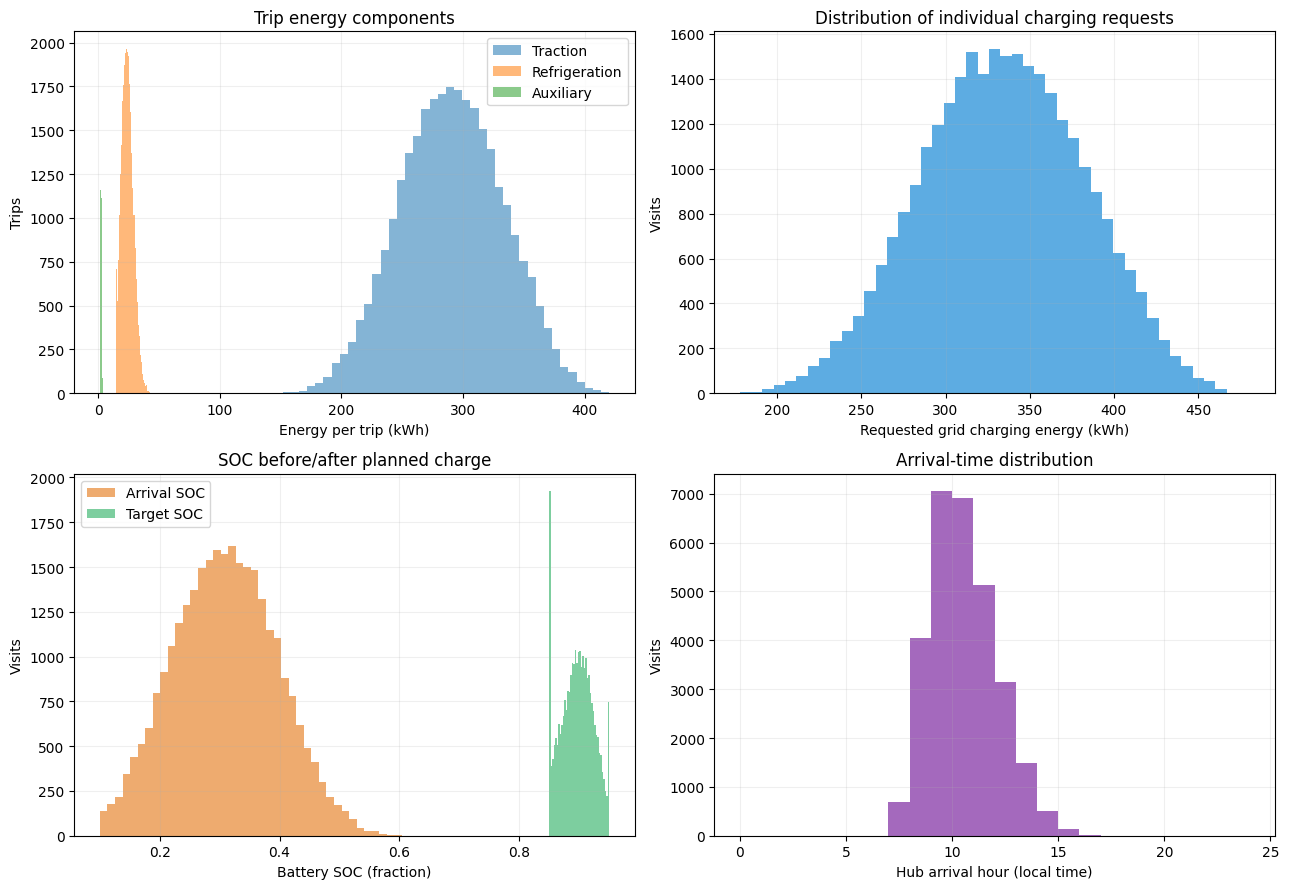

Mean trip distance: 228.6 km
Mean trip battery energy: 317.1 kWh
Mean grid request: 333.7 kWh


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
ax = axes[0, 0]
for col, label in [("Traction Energy (kWh)", "Traction"), ("Refrigeration Energy (kWh)", "Refrigeration"), ("Auxiliary Energy (kWh)", "Auxiliary")]:
    ax.hist(truck_forecast[col], bins=40, alpha=0.55, label=label)
ax.set(xlabel="Energy per trip (kWh)", ylabel="Trips", title="Trip energy components"); ax.legend(); ax.grid(alpha=0.2)
ax = axes[0, 1]
ax.hist(truck_forecast["Energy To Charge (kWh)"], bins=45, color="#3498db", alpha=0.8)
ax.set(xlabel="Requested grid charging energy (kWh)", ylabel="Visits", title="Distribution of individual charging requests"); ax.grid(alpha=0.2)
ax = axes[1, 0]
ax.hist(truck_forecast["Arrival SOC"], bins=40, alpha=0.65, label="Arrival SOC", color="#e67e22")
ax.hist(truck_forecast["Target SOC"], bins=40, alpha=0.6, label="Target SOC", color="#27ae60")
ax.set(xlabel="Battery SOC (fraction)", ylabel="Visits", title="SOC before/after planned charge"); ax.legend(); ax.grid(alpha=0.2)
ax = axes[1, 1]
arrivals_hour = truck_forecast["Arrival Time"].dt.hour + truck_forecast["Arrival Time"].dt.minute/60
ax.hist(arrivals_hour, bins=np.arange(0, 25), color="#8e44ad", alpha=0.8)
ax.set(xlabel="Hub arrival hour (local time)", ylabel="Visits", title="Arrival-time distribution"); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()
print("Mean trip distance:", f"{truck_forecast['Trip Distance (km)'].mean():.1f} km")
print("Mean trip battery energy:", f"{truck_forecast['Trip Energy (kWh)'].mean():.1f} kWh")
print("Mean grid request:", f"{truck_forecast['Energy To Charge (kWh)'].mean():.1f} kWh")

## 6. Hourly charging demand from the forecast events

`hub.forecast_to_hourly_load` integrates each event's SOC-dependent charging-power curve from its *actual FCFS connection time* into hourly energy bins. It checks time-unit consistency and preserves fractional hours and daylight-saving timestamps.

`n_sessions` is the **maximum simultaneous** chargers occupied in each hour. `n_sessions_touching` counts all sessions that overlap that hour; this can exceed charger count when chargers turn over within an hour. **Hourly average load is not an instantaneous power limit.**

In [7]:
heavy_haul_load = hub.forecast_to_hourly_load(truck_forecast, HOURS, step_minutes=STEP_MINUTES)
forecast_energy_kwh = truck_forecast["Energy To Charge (kWh)"].sum()
hourly_energy_kwh = heavy_haul_load["load_kw"].sum()
energy_error_kwh = hourly_energy_kwh - forecast_energy_kwh
assert abs(energy_error_kwh) < 0.01, f"Charging energy imbalance: {energy_error_kwh} kWh"
assert heavy_haul_load["n_sessions"].max() <= N_CHARGERS, "Charger occupancy exceeds installed charging points"
assert heavy_haul_load["load_kw"].max() <= N_CHARGERS * hub.CHARGER_POWER_KW + 1e-6, "Charging power exceeds installed nameplate rating"
assert (heavy_haul_load["load_kw"].resample("ME").sum() > 0).all(), "No charging demand in one or more months"
print(f"Annual requested / simulated grid electricity: {forecast_energy_kwh/1e6:.4f} / {hourly_energy_kwh/1e6:.4f} GWh")
print(f"Energy conservation error: {energy_error_kwh:.7f} kWh")
print(f"Hourly-average peak load: {heavy_haul_load['load_mw'].max():.2f} MW | Mean: {heavy_haul_load['load_mw'].mean():.2f} MW")
print(f"Maximum concurrent sessions: {heavy_haul_load['n_sessions'].max():.0f} / {N_CHARGERS}")
display(heavy_haul_load.head(12))

Annual requested / simulated grid electricity: 9.7286 / 9.7286 GWh
Energy conservation error: 0.0000000 kWh
Hourly-average peak load: 7.56 MW | Mean: 1.11 MW
Maximum concurrent sessions: 42 / 42


,n_sessions,mean_active_chargers,n_sessions_touching,load_kw,load_mw
2023-01-01 00:00:00+11:00,0,0.000000,0,0.000000,0.000000
2023-01-01 01:00:00+11:00,0,0.000000,0,0.000000,0.000000
2023-01-01 02:00:00+11:00,0,0.000000,0,0.000000,0.000000
2023-01-01 03:00:00+11:00,0,0.000000,0,0.000000,0.000000
2023-01-01 04:00:00+11:00,0,0.000000,0,0.000000,0.000000
2023-01-01 05:00:00+11:00,0,0.000000,0,0.000000,0.000000
2023-01-01 06:00:00+11:00,0,0.000000,0,0.000000,0.000000
2023-01-01 07:00:00+11:00,0,0.000000,0,0.000000,0.000000
2023-01-01 08:00:00+11:00,1,0.461313,1,103.850696,0.103851
2023-01-01 09:00:00+11:00,7,4.149360,7,850.386535,0.850387


## 7. Charger-count scenarios — common trip forecasts

All scenarios use identical `EV_001`–`EV_100` identities, arrivals, departures, SOC and grid-energy requests from `truck_forecast`. Only physical CCS charging point count and associated FCFS assignment change. Missed deadlines are diagnostic: the current schedule completes charging even after a deadline; the next-trip SOC is still based on the *planned* target. These are **unconstrained-delivery reference loads**, not proof of EPM feasibility.

,Scenario,Charging points,Peak (MW),Mean (MW),Annual energy (GWh),Peak simultaneous sessions,Missed departure deadlines,Mean queue wait (min)
0,Constrained: 28 × CCS 250 kW,28,5.278,1.111,9.729,28,3668,47.339
1,Reference: 42 × CCS 250 kW,42,7.555,1.111,9.729,42,7,5.383
2,Expanded: 56 × CCS 250 kW,56,9.586,1.111,9.729,56,0,0.055


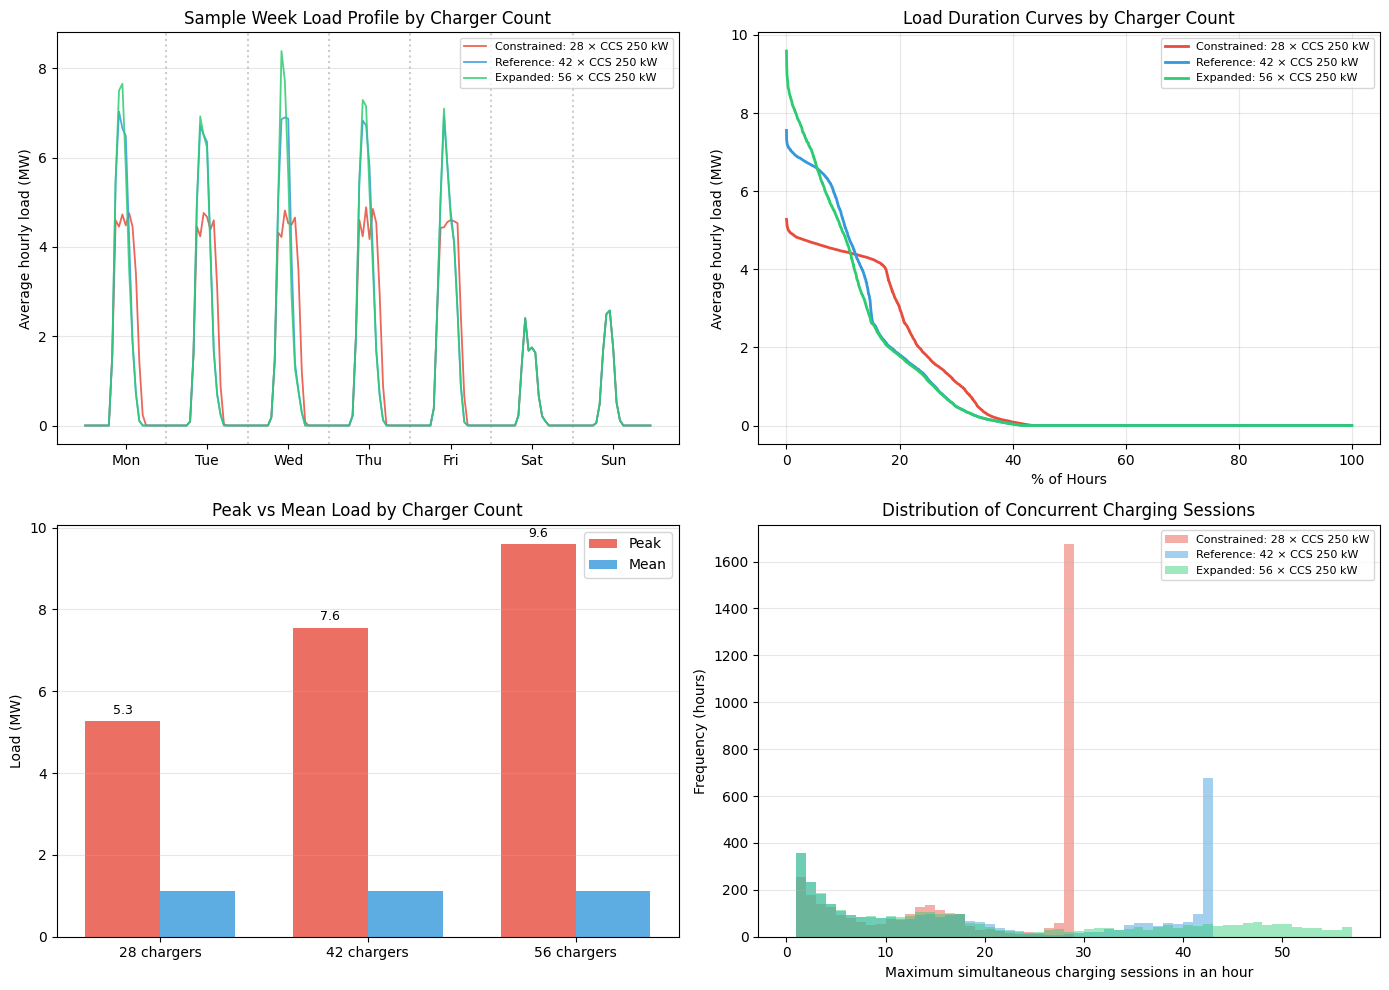

Forecast-derived infrastructure scenario results exported to output\ev_charging/


In [8]:
# ============================================================================
# FORECAST-BASED CHARGER-COUNT SCENARIOS — SHARED VEHICLE EVENTS, FCFS SCHEDULES
# ============================================================================
FORECAST_CHARGER_SCENARIOS = {
    "constrained_28": {"name": "Constrained: 28 × CCS 250 kW", "n_chargers": 28, "color": "#e74c3c"},
    "reference_42": {"name": "Reference: 42 × CCS 250 kW", "n_chargers": 42, "color": "#3498db"},
    "expanded_56": {"name": "Expanded: 56 × CCS 250 kW", "n_chargers": 56, "color": "#2ecc71"},
}

forecast_scenario_events = {}
forecast_scenario_results = {}
forecast_scenario_summary = []
forecast_energy_kwh = truck_forecast["Energy To Charge (kWh)"].sum()

for key, config in FORECAST_CHARGER_SCENARIOS.items():
    n_chargers = config["n_chargers"]
    scheduled = truck_forecast.copy() if n_chargers == 42 else hub.reschedule_forecast(truck_forecast, n_chargers=n_chargers)
    hourly = heavy_haul_load.copy() if n_chargers == 42 else hub.forecast_to_hourly_load(scheduled, HOURS, step_minutes=STEP_MINUTES)
    assert scheduled["Id EV"].equals(truck_forecast["Id EV"]), "Fleet identities changed between scenarios"
    assert abs(hourly["load_kw"].sum() - forecast_energy_kwh) < 0.01, "Energy conservation failed"
    assert hourly["n_sessions"].max() <= n_chargers, "Charger occupancy exceeds physical count"
    assert hourly["load_kw"].max() <= n_chargers * hub.CHARGER_POWER_KW + 1e-6, "Peak power exceeds site rating"
    forecast_scenario_events[key] = scheduled
    forecast_scenario_results[key] = hourly
    forecast_scenario_summary.append({"Scenario": config["name"], "Charging points": n_chargers, "Peak (MW)": hourly["load_mw"].max(), "Mean (MW)": hourly["load_mw"].mean(), "Annual energy (GWh)": hourly["load_mw"].sum()/1000, "Peak simultaneous sessions": int(hourly["n_sessions"].max()), "Missed departure deadlines": int((~scheduled["Deadline Feasible"]).sum()), "Mean queue wait (min)": scheduled["Queue Wait (min)"].mean()})

forecast_scenario_summary_df = pd.DataFrame(forecast_scenario_summary)
display(forecast_scenario_summary_df.round(3))

# 2 × 2 dashboard modelled on the original SCENARIO COMPARISON VISUALIZATION.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
week_start = SAMPLE_WEEK_START
week_end = SAMPLE_WEEK_END
ax = axes[0, 0]
for key, config in FORECAST_CHARGER_SCENARIOS.items():
    series = forecast_scenario_results[key].loc[(forecast_scenario_results[key].index >= week_start) & (forecast_scenario_results[key].index < week_end), "load_mw"]
    ax.plot(np.arange(len(series)), series.values, label=config["name"], color=config["color"], linewidth=1.3, alpha=0.85)
for day_idx in range(1, 7):
    ax.axvline(day_idx*24, color="grey", linestyle=":", alpha=0.4)
ax.set_xticks([12+i*24 for i in range(7)])
ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_ylabel("Average hourly load (MW)")
ax.set_title("Sample Week Load Profile by Charger Count")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis="y")

ax = axes[0, 1]
for key, config in FORECAST_CHARGER_SCENARIOS.items():
    load = np.sort(forecast_scenario_results[key]["load_mw"].values)[::-1]
    ax.plot(np.linspace(0, 100, len(load)), load, color=config["color"], label=config["name"], linewidth=2)
ax.set_xlabel("% of Hours")
ax.set_ylabel("Average hourly load (MW)")
ax.set_title("Load Duration Curves by Charger Count")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
keys = list(FORECAST_CHARGER_SCENARIOS)
x = np.arange(len(keys))
peaks = [forecast_scenario_results[k]["load_mw"].max() for k in keys]
means = [forecast_scenario_results[k]["load_mw"].mean() for k in keys]
peak_bars = ax.bar(x-0.18, peaks, 0.36, color="#e74c3c", label="Peak", alpha=0.8)
ax.bar(x+0.18, means, 0.36, color="#3498db", label="Mean", alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f"{FORECAST_CHARGER_SCENARIOS[k]['n_chargers']} chargers" for k in keys])
ax.set_ylabel("Load (MW)")
ax.set_title("Peak vs Mean Load by Charger Count")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
for bar, value in zip(peak_bars, peaks):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1, f"{value:.1f}", ha="center", va="bottom", fontsize=9)

ax = axes[1, 1]
max_sessions = max(int(df["n_sessions"].max()) for df in forecast_scenario_results.values())
for key, config in FORECAST_CHARGER_SCENARIOS.items():
    counts = forecast_scenario_results[key]["n_sessions"]
    ax.hist(counts[counts>0], bins=np.arange(0, max_sessions+2), alpha=0.45, color=config["color"], label=config["name"])
ax.set_xlabel("Maximum simultaneous charging sessions in an hour")
ax.set_ylabel("Frequency (hours)")
ax.set_title("Distribution of Concurrent Charging Sessions")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

# Export only forecast-derived charging infrastructure scenarios.
forecast_export = pd.DataFrame(index=HOURS)
for key, result in forecast_scenario_results.items():
    forecast_export[f"{key}_load_kw"] = result["load_kw"]
    forecast_export[f"{key}_load_mw"] = result["load_mw"]
    forecast_export[f"{key}_concurrent_sessions"] = result["n_sessions"]
forecast_export.to_csv(OUTPUT_DIR / f"ballarat_hub_{YEAR}_capacity_scenarios_hourly.csv", index_label="datetime")
forecast_scenario_summary_df.to_csv(OUTPUT_DIR / f"ballarat_hub_{YEAR}_capacity_scenarios_summary.csv", index=False)
print(f"Forecast-derived infrastructure scenario results exported to {OUTPUT_DIR}/")

## 8. Truck charging load visualisations

Every graph in this section uses `heavy_haul_load`, which comes exclusively from the exported vehicle-level schedule. Day-of-week and hour-of-day are in `Australia/Melbourne` local time.

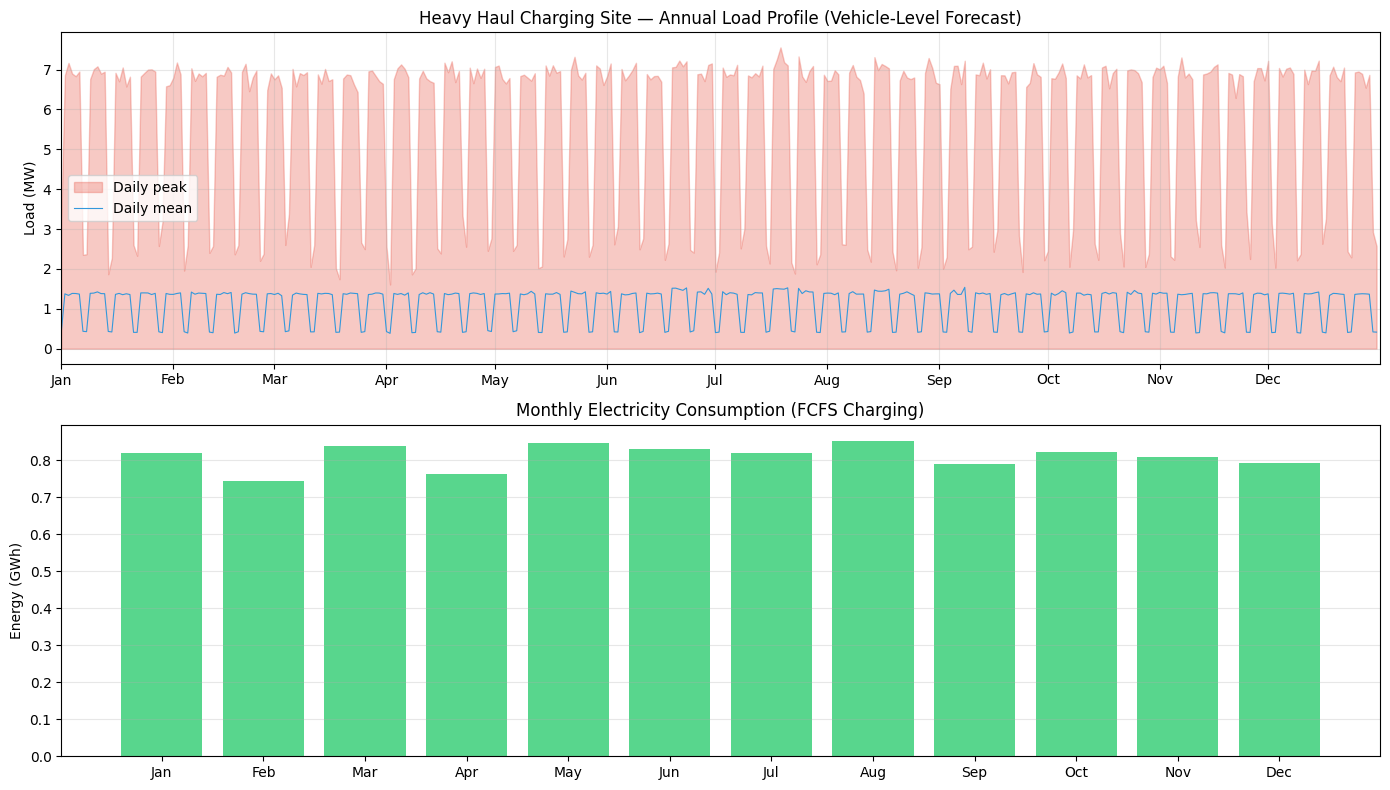

In [9]:
# 8.1 Annual load profile — forecast-derived hourly grid electricity.
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
daily_load = heavy_haul_load["load_mw"].resample("D").agg(["max", "mean"])
ax = axes[0]
ax.fill_between(daily_load.index, daily_load["max"], alpha=0.3, color="#e74c3c", label="Daily peak")
ax.plot(daily_load.index, daily_load["mean"], color="#3498db", linewidth=0.8, label="Daily mean")
ax.set_ylabel("Load (MW)")
ax.set_title("Heavy Haul Charging Site — Annual Load Profile (Vehicle-Level Forecast)")
ax.legend()
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b", tz=TIMEZONE))
ax.set_xlim(HOURS[0], HOURS[-1])

monthly_energy = heavy_haul_load["load_mw"].resample("ME").sum() / 1000  # GWh
ax = axes[1]
ax.bar(np.arange(12), monthly_energy.values, color="#2ecc71", alpha=0.8)
ax.set_xticks(np.arange(12))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Energy (GWh)")
ax.set_title("Monthly Electricity Consumption (FCFS Charging)")
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

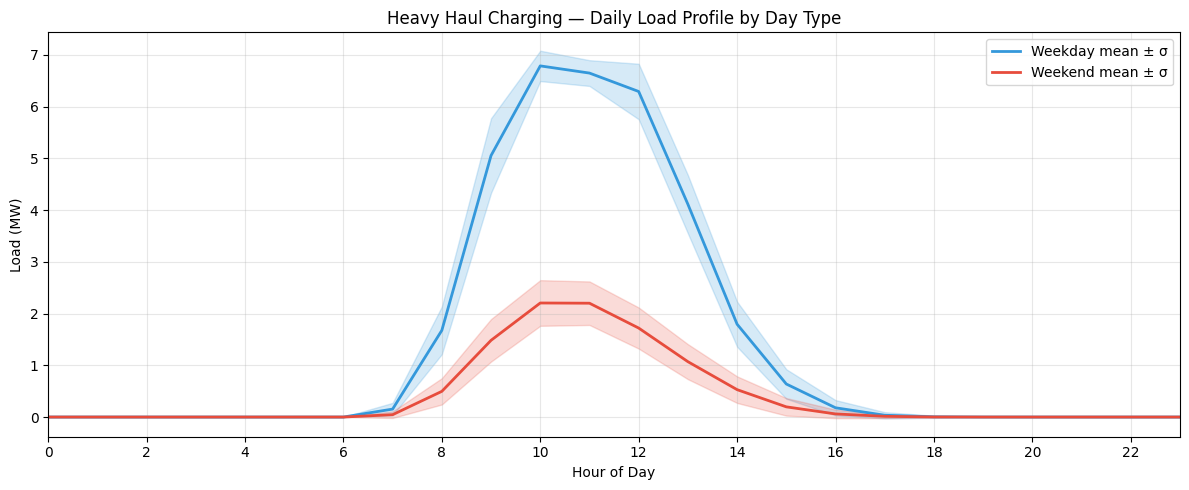

In [10]:
# 8.2 Typical day profiles by day type — forecast-derived
heavy_haul_load['hour'] = heavy_haul_load.index.hour
heavy_haul_load['dayofweek'] = heavy_haul_load.index.dayofweek
heavy_haul_load['is_weekend'] = heavy_haul_load['dayofweek'] >= 5

weekday_profile = heavy_haul_load[~heavy_haul_load['is_weekend']].groupby('hour')['load_mw'].agg(['mean', 'std', 'max'])
weekend_profile = heavy_haul_load[heavy_haul_load['is_weekend']].groupby('hour')['load_mw'].agg(['mean', 'std', 'max'])

fig, ax = plt.subplots(figsize=(12, 5))

ax.fill_between(weekday_profile.index, 
                weekday_profile['mean'] - weekday_profile['std'],
                weekday_profile['mean'] + weekday_profile['std'],
                alpha=0.2, color='#3498db')
ax.plot(weekday_profile.index, weekday_profile['mean'], color='#3498db', linewidth=2, label='Weekday mean ± σ')

ax.fill_between(weekend_profile.index,
                weekend_profile['mean'] - weekend_profile['std'],
                weekend_profile['mean'] + weekend_profile['std'],
                alpha=0.2, color='#e74c3c')
ax.plot(weekend_profile.index, weekend_profile['mean'], color='#e74c3c', linewidth=2, label='Weekend mean ± σ')

ax.set_xlabel('Hour of Day')
ax.set_ylabel('Load (MW)')
ax.set_title('Heavy Haul Charging — Daily Load Profile by Day Type')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 23)
ax.set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

# Clean up temp columns
heavy_haul_load.drop(columns=['hour', 'dayofweek', 'is_weekend'], inplace=True)

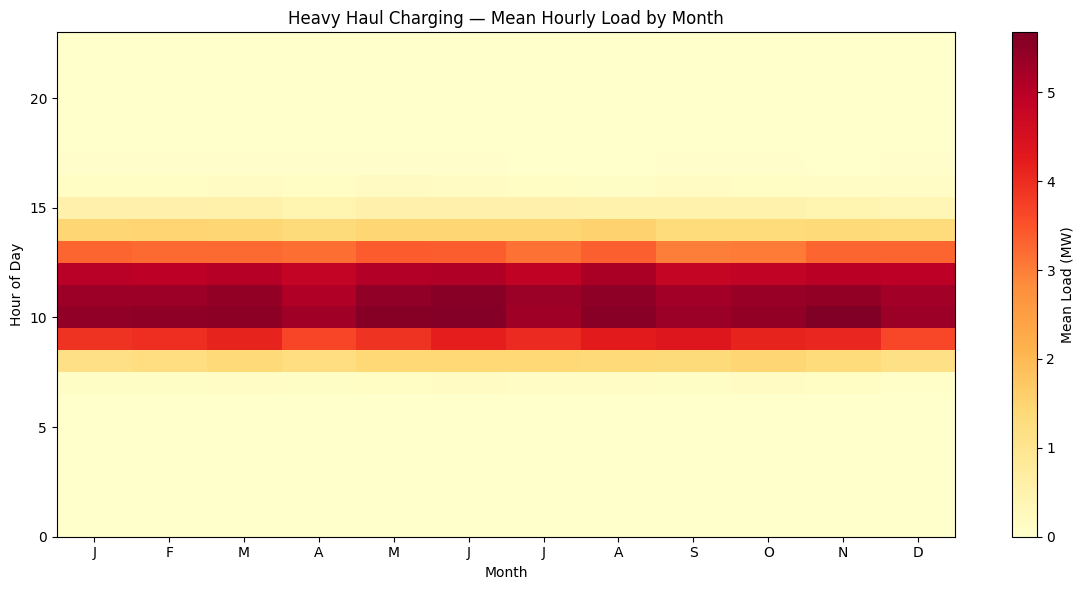

In [11]:
# 8.3 Heatmap: hour vs month
heatmap_data = heavy_haul_load['load_mw'].copy().to_frame()
heatmap_data['hour'] = heatmap_data.index.hour
heatmap_data['month'] = heatmap_data.index.month

pivot = heatmap_data.pivot_table(index='hour', columns='month', values='load_mw', aggfunc='mean')

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.pcolormesh(pivot.columns, pivot.index, pivot.values, cmap='YlOrRd', shading='auto')
plt.colorbar(im, ax=ax, label='Mean Load (MW)')
ax.set_xlabel('Month')
ax.set_ylabel('Hour of Day')
ax.set_title('Heavy Haul Charging — Mean Hourly Load by Month')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
ax.set_ylim(0, 23)  # Show all local hours, including overnight charging

plt.tight_layout()
plt.show()

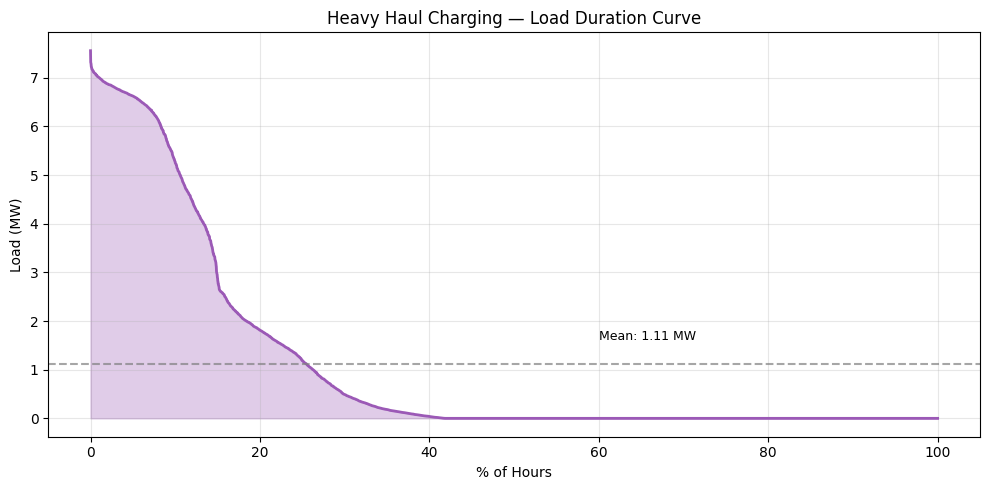

In [12]:
# 8.4 Load duration curve
sorted_load = np.sort(heavy_haul_load['load_mw'].values)[::-1]
x_pct = np.linspace(0, 100, len(sorted_load))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_pct, sorted_load, color='#9b59b6', linewidth=2)
ax.fill_between(x_pct, sorted_load, alpha=0.3, color='#9b59b6')
ax.set_xlabel('% of Hours')
ax.set_ylabel('Load (MW)')
ax.set_title('Heavy Haul Charging — Load Duration Curve')
ax.grid(True, alpha=0.3)

# Annotate key points
ax.axhline(y=heavy_haul_load['load_mw'].mean(), color='grey', linestyle='--', alpha=0.7)
ax.annotate(f'Mean: {heavy_haul_load["load_mw"].mean():.2f} MW', 
            xy=(50, heavy_haul_load['load_mw'].mean()), xytext=(60, heavy_haul_load['load_mw'].mean() + 0.5),
            fontsize=9)

plt.tight_layout()
plt.show()

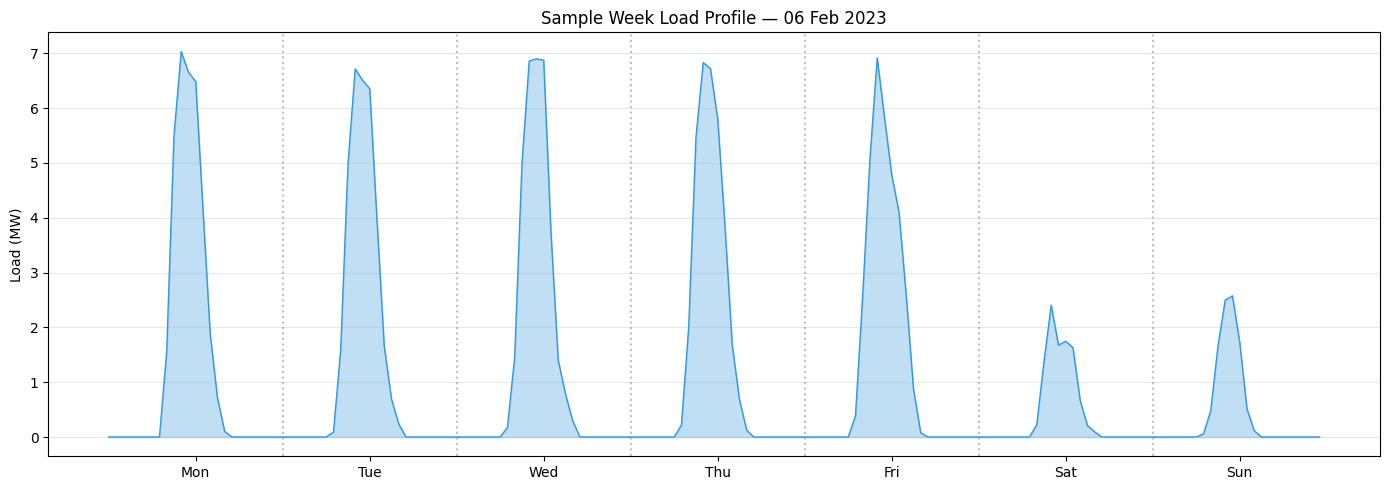

In [13]:
# 8.5 Sample week view
sample_week_start = SAMPLE_WEEK_START  # first Monday in February
sample_week_end = SAMPLE_WEEK_END
sample_week = heavy_haul_load.loc[(heavy_haul_load.index >= sample_week_start) & (heavy_haul_load.index < sample_week_end)]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(range(len(sample_week)), sample_week['load_mw'].values, color='#3498db', linewidth=1)
ax.fill_between(range(len(sample_week)), sample_week['load_mw'].values, alpha=0.3, color='#3498db')

# Day separators
for d in range(1, 7):
    ax.axvline(x=d*24, color='grey', linestyle=':', alpha=0.5)

ax.set_xticks([12 + i*24 for i in range(7)])
ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax.set_ylabel('Load (MW)')
ax.set_title(f'Sample Week Load Profile — {sample_week_start.strftime("%d %b %Y")}')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## 9. Forecast-based summary and exports

The canonical outputs have unambiguous names, and no legacy truck-scenario CSVs are generated. Requested energy is grid-side; the forecast module already accounts for 95% charger efficiency.

In [14]:
truck_summary = pd.DataFrame([{
    "year": YEAR,
    "fleet_size": hub.FLEET_SIZE,
    "events": len(truck_forecast),
    "charging_points": N_CHARGERS,
    "mean_trip_distance_km": truck_forecast["Trip Distance (km)"].mean(),
    "mean_trip_energy_kwh": truck_forecast["Trip Energy (kWh)"].mean(),
    "mean_grid_request_kwh": truck_forecast["Energy To Charge (kWh)"].mean(),
    "requested_grid_energy_gwh": forecast_energy_kwh / 1e6,
    "hourly_grid_energy_gwh": hourly_energy_kwh / 1e6,
    "energy_reconciliation_error_kwh": energy_error_kwh,
    "peak_hourly_average_mw": heavy_haul_load["load_mw"].max(),
    "mean_hourly_mw": heavy_haul_load["load_mw"].mean(),
    "max_simultaneous_sessions": int(heavy_haul_load["n_sessions"].max()),
    "missed_fcfs_deadlines": int((~truck_forecast["Deadline Feasible"]).sum())
}])
display(truck_summary.round(4))
truck_summary.to_csv(OUTPUT_DIR / f"ballarat_hub_{YEAR}_summary.csv", index=False)
heavy_haul_load.to_csv(OUTPUT_DIR / f"ballarat_hub_{YEAR}_hourly_load.csv", index_label="datetime")
weather_and_trucks = weather[["temp_ambient"]].join(heavy_haul_load)
weather_and_trucks.to_csv(OUTPUT_DIR / f"ballarat_hub_{YEAR}_weather_and_hourly_load.csv", index_label="datetime")
print("Exported:")
for suffix in ["_EPM.csv", "_detailed.csv", "_hourly_load.csv", "_weather_and_hourly_load.csv", "_summary.csv", "_capacity_scenarios_hourly.csv", "_capacity_scenarios_summary.csv"]:
    print(" ", OUTPUT_DIR / f"ballarat_hub_{YEAR}{suffix}")

,year,fleet_size,events,charging_points,mean_trip_distance_km,mean_trip_energy_kwh,mean_grid_request_kwh,requested_grid_energy_gwh,hourly_grid_energy_gwh,energy_reconciliation_error_kwh,peak_hourly_average_mw,mean_hourly_mw,max_simultaneous_sessions,missed_fcfs_deadlines
0,2023,100,29150,42,228.639,317.0647,333.7413,9.7286,9.7286,0.0,7.5552,1.1106,42,7


Exported:
  output\ev_charging\ballarat_hub_2023_EPM.csv
  output\ev_charging\ballarat_hub_2023_detailed.csv
  output\ev_charging\ballarat_hub_2023_hourly_load.csv
  output\ev_charging\ballarat_hub_2023_weather_and_hourly_load.csv
  output\ev_charging\ballarat_hub_2023_summary.csv
  output\ev_charging\ballarat_hub_2023_capacity_scenarios_hourly.csv
  output\ev_charging\ballarat_hub_2023_capacity_scenarios_summary.csv


## 10. Separate bus depot model (76 buses)

The bus depot remains an **independent illustrative model**, not part of `forecast_ev_hub_schedule.py` and not represented in the truck EPM CSV. Its daily charging schedule is repeated across the year for site-load comparison. The bus hourly profile is adjusted to carry charging past midnight into the next calendar day instead of dropping that energy. It is not a per-bus operational forecast, and its assumptions should be validated before EPM integration.

In [15]:
# ============================================================================
# BUS SPECIFICATIONS
# ============================================================================

@dataclass
class BusSpec:
    """Electric bus specifications."""
    name: str
    battery_kwh: float
    max_charge_kw: float         # Depot charging rate
    consumption_kwh_km: float    # Energy consumption per km
    passenger_capacity: int
    
# Volvo BZL + Volgren Optimus (470 kWh config)
VOLVO_BZL = BusSpec(
    name="Volvo BZL Electric (470 kWh)",
    battery_kwh=470,
    max_charge_kw=150,           # CCS depot charging
    consumption_kwh_km=1.1,      # Efficient city bus
    passenger_capacity=70,
)

# BYD K9 + Volgren Optimus
BYD_K9 = BusSpec(
    name="BYD K9 (324 kWh)",
    battery_kwh=324,
    max_charge_kw=60,            # AC depot charging (2 x 30 kW)
    consumption_kwh_km=1.3,      # Slightly higher consumption
    passenger_capacity=61,
)

BUS_OPTIONS = {
    'volvo_bzl': VOLVO_BZL,
    'byd_k9': BYD_K9,
}

# ============================================================================
# BALLARAT BUS NETWORK PARAMETERS (from GTFS analysis)
# ============================================================================

@dataclass
class BusNetworkParams:
    """Bus network operational parameters."""
    name: str
    fleet_size: int
    daily_km_per_bus: float      # Average km per bus per day
    service_start_hour: float    # First bus departure
    service_end_hour: float      # Last bus return to depot
    peak_buses_active: int       # Max concurrent buses in service
    
BALLARAT_BUS_NETWORK = BusNetworkParams(
    name="CDC Ballarat",
    fleet_size=76,
    daily_km_per_bus=257,        # From GTFS analysis
    service_start_hour=5.0,      # 05:00
    service_end_hour=22.0,       # ~22:00 (last return after 21:30 service)
    peak_buses_active=70,        # Assume ~92% of fleet active at peak
)

# ============================================================================
# DEPOT CHARGING MODEL
# ============================================================================

@dataclass
class DepotChargingModel:
    """Model for overnight depot charging of bus fleet."""
    bus: BusSpec
    network: BusNetworkParams
    charger_power_kw: float = None      # Override bus max if depot-limited
    charging_efficiency: float = 0.92   # AC charging efficiency
    min_soc_return: float = 0.20        # Buses return with ~20% SOC
    target_soc: float = 0.95            # Charge to 95% overnight
    
    def __post_init__(self):
        if self.charger_power_kw is None:
            self.charger_power_kw = self.bus.max_charge_kw
    
    @property
    def charging_window_hours(self) -> float:
        """Available hours for overnight charging."""
        return 24 - self.network.service_end_hour + self.network.service_start_hour
    
    @property
    def energy_per_bus_kwh(self) -> float:
        """Energy consumed per bus per day."""
        return self.network.daily_km_per_bus * self.bus.consumption_kwh_km
    
    @property
    def charge_needed_kwh(self) -> float:
        """Energy to replenish per bus (accounting for efficiency)."""
        return self.energy_per_bus_kwh / self.charging_efficiency
    
    @property
    def charge_time_hours(self) -> float:
        """Time to charge one bus."""
        return self.charge_needed_kwh / self.charger_power_kw
    
    def min_chargers_needed(self) -> int:
        """Minimum chargers for sequential charging within window."""
        # Each charger can charge N buses where N = window / charge_time
        buses_per_charger = self.charging_window_hours / self.charge_time_hours
        return int(np.ceil(self.network.fleet_size / buses_per_charger))
    
    def generate_load_profile(self, 
                               n_chargers: int,
                               stagger_minutes: int = 15) -> pd.DataFrame:
        """
        Generate hourly depot charging load profile.
        
        Assumes buses return staggered and are assigned to chargers in order.
        """
        # Simulate bus returns (staggered over last 2 hours of service)
        return_start = self.network.service_end_hour - 2.0
        return_end = self.network.service_end_hour
        
        rng = np.random.default_rng(42)
        return_times = rng.uniform(return_start, return_end, self.network.fleet_size)
        return_times = np.sort(return_times)
        
        # Assign buses to chargers (round-robin)
        charger_queues = [[] for _ in range(n_chargers)]
        charger_available = [return_start] * n_chargers
        
        for bus_id, return_time in enumerate(return_times):
            # Find first available charger
            next_charger = np.argmin(charger_available)
            start_charge = max(return_time, charger_available[next_charger])
            end_charge = start_charge + self.charge_time_hours
            
            charger_queues[next_charger].append({
                'bus_id': bus_id,
                'start': start_charge,
                'end': end_charge,
            })
            charger_available[next_charger] = end_charge
        
        # Build a repeating 24-hour load profile. Sessions continuing beyond
        # midnight must contribute to the next day's 00:00–05:00 slots.
        hours = np.arange(24)
        load_kw = np.zeros(24)
        n_charging = np.zeros(24, dtype=int)
        occupancy_events = [[] for _ in range(24)]
        for charger_queue in charger_queues:
            for session in charger_queue:
                for hour_number in range(int(np.floor(session["start"])), int(np.ceil(session["end"]))):
                    piece_start = max(float(hour_number), session["start"])
                    piece_end = min(float(hour_number + 1), session["end"])
                    if piece_end <= piece_start:
                        continue
                    hour = hour_number % 24
                    load_kw[hour] += self.charger_power_kw * (piece_end - piece_start)
                    occupancy_events[hour].extend([(piece_start, 1), (piece_end, -1)])
        for hour, edges in enumerate(occupancy_events):
            active = peak_active = 0
            for _, delta in sorted(edges, key=lambda event: (event[0], event[1])):
                active += delta
                peak_active = max(peak_active, active)
            n_charging[hour] = peak_active
        expected_kwh = self.network.fleet_size * self.charge_needed_kwh
        assert abs(load_kw.sum() - expected_kwh) < 0.01, "Bus daily energy balance failed"
        assert n_charging.max() <= n_chargers, "Bus charging exceeds installed points"

        return pd.DataFrame({
            'hour': hours,
            'load_kw': load_kw,
            'load_mw': load_kw / 1000,
            'n_charging': n_charging,
        })

# ============================================================================
# ANALYZE BUS CHARGING SCENARIOS
# ============================================================================

print("=" * 80)
print("BALLARAT BUS FLEET — DEPOT CHARGING ANALYSIS")
print("=" * 80)

for bus_key, bus in BUS_OPTIONS.items():
    model = DepotChargingModel(bus=bus, network=BALLARAT_BUS_NETWORK)
    
    print(f"\n{bus.name}")
    print("-" * 60)
    print(f"  Daily consumption: {model.energy_per_bus_kwh:.0f} kWh/bus")
    print(f"  Charge needed: {model.charge_needed_kwh:.0f} kWh/bus (incl. losses)")
    print(f"  Charge time: {model.charge_time_hours:.1f} hours @ {model.charger_power_kw} kW")
    print(f"  Charging window: {model.charging_window_hours:.1f} hours")
    print(f"  Minimum chargers needed: {model.min_chargers_needed()}")
    
    # Check if battery is sufficient
    usable_kwh = bus.battery_kwh * (model.target_soc - model.min_soc_return)
    if model.energy_per_bus_kwh > usable_kwh:
        print(f"  ⚠️  WARNING: Daily consumption exceeds usable battery!")
    else:
        margin = (usable_kwh - model.energy_per_bus_kwh) / model.energy_per_bus_kwh * 100
        print(f"  ✓ Battery margin: {margin:.0f}% reserve")

BALLARAT BUS FLEET — DEPOT CHARGING ANALYSIS

Volvo BZL Electric (470 kWh)
------------------------------------------------------------
  Daily consumption: 283 kWh/bus
  Charge needed: 307 kWh/bus (incl. losses)
  Charge time: 2.0 hours @ 150 kW
  Charging window: 7.0 hours
  Minimum chargers needed: 23
  ✓ Battery margin: 25% reserve

BYD K9 (324 kWh)
------------------------------------------------------------
  Daily consumption: 334 kWh/bus
  Charge needed: 363 kWh/bus (incl. losses)
  Charge time: 6.1 hours @ 60 kW
  Charging window: 7.0 hours
  Minimum chargers needed: 66
  ⚠️  WARNING: Daily consumption exceeds usable battery!



BUS DEPOT CHARGING SCENARIOS (Volvo BZL Fleet)

MINIMUM (23 chargers):
  Peak load: 3.45 MW
  Daily energy: 23.4 MWh
  Peak simultaneous charging: 23 buses

COMFORTABLE (28 chargers):
  Peak load: 4.20 MW
  Daily energy: 23.4 MWh
  Peak simultaneous charging: 28 buses

ONE_PER_BUS (76 chargers):
  Peak load: 9.00 MW
  Daily energy: 23.4 MWh
  Peak simultaneous charging: 76 buses


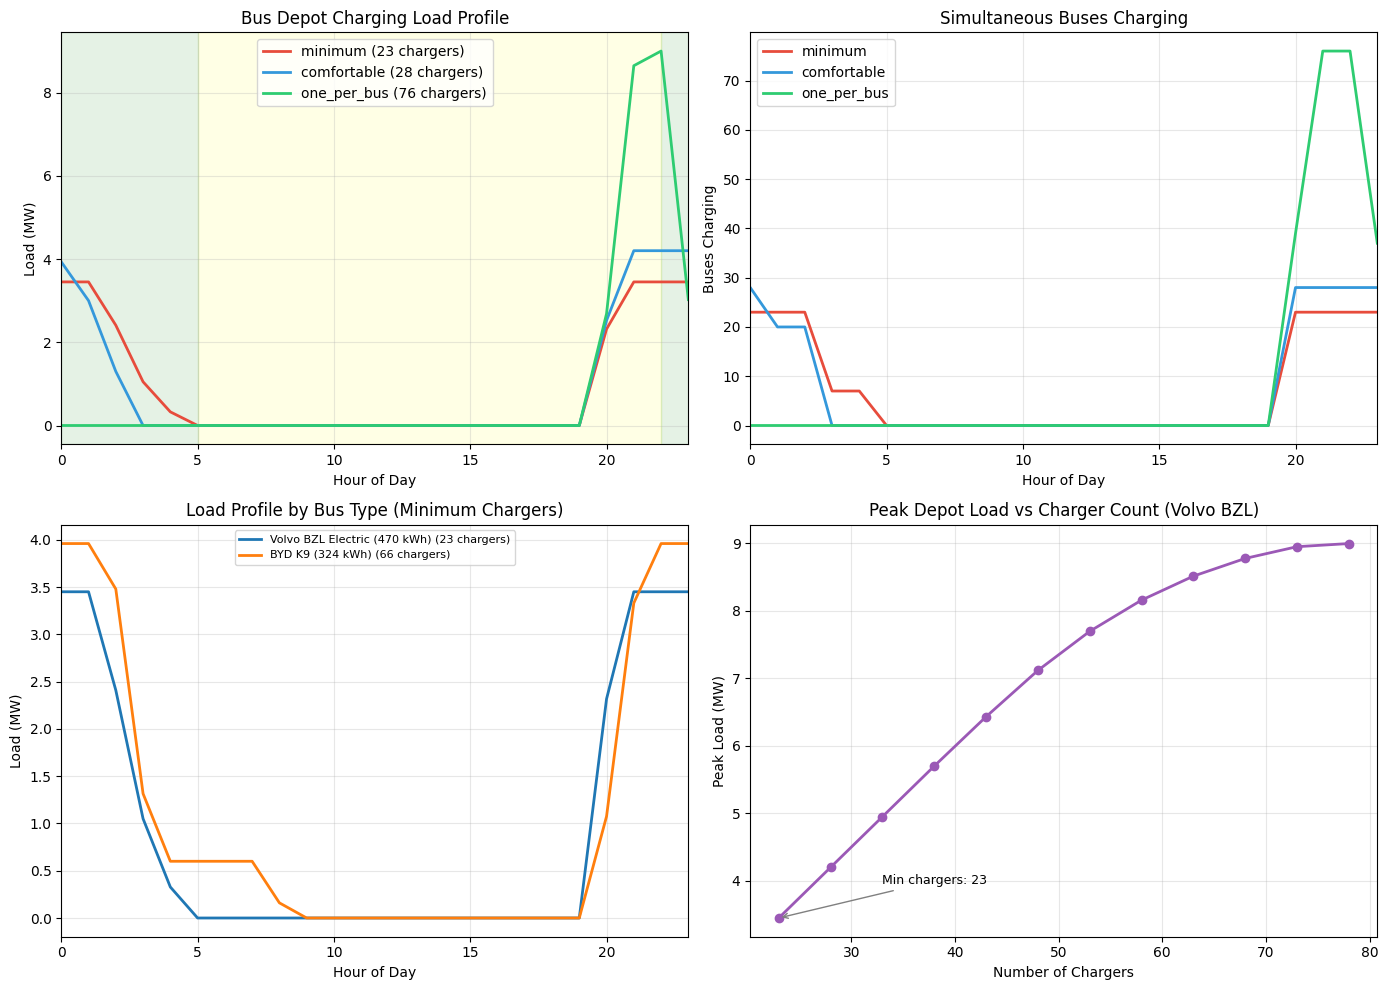


KEY FINDINGS

Ballarat Bus Fleet Electrification:
- Fleet size: 76 buses
- Daily consumption: ~21.5 MWh (fleet total)
- Recommended: Volvo BZL (470 kWh) for battery margin
- Minimum 23 CCS chargers @ 150 kW each
- Peak depot load: 3.5 MW
- Charging window: 22:00 - 05:00 (overnight)



In [16]:
# ============================================================================
# GENERATE BUS DEPOT LOAD PROFILES
# ============================================================================

# Scenario: Volvo BZL fleet with sufficient chargers
volvo_model = DepotChargingModel(bus=VOLVO_BZL, network=BALLARAT_BUS_NETWORK)
min_chargers_volvo = volvo_model.min_chargers_needed()

# Generate profiles for different charger counts
charger_scenarios = {
    'minimum': min_chargers_volvo,
    'comfortable': int(min_chargers_volvo * 1.25),
    'one_per_bus': 76,
}

bus_load_profiles = {}
for scenario_name, n_chargers in charger_scenarios.items():
    profile = volvo_model.generate_load_profile(n_chargers=n_chargers)
    bus_load_profiles[scenario_name] = profile
    
print("\n" + "=" * 80)
print("BUS DEPOT CHARGING SCENARIOS (Volvo BZL Fleet)")
print("=" * 80)

for name, n in charger_scenarios.items():
    profile = bus_load_profiles[name]
    peak_mw = profile['load_mw'].max()
    total_mwh = profile['load_mw'].sum()
    peak_charging = profile['n_charging'].max()
    print(f"\n{name.upper()} ({n} chargers):")
    print(f"  Peak load: {peak_mw:.2f} MW")
    print(f"  Daily energy: {total_mwh:.1f} MWh")
    print(f"  Peak simultaneous charging: {peak_charging} buses")

# Visualize
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Load profiles by scenario
ax = axes[0, 0]
colors = {'minimum': '#e74c3c', 'comfortable': '#3498db', 'one_per_bus': '#2ecc71'}
for name, profile in bus_load_profiles.items():
    ax.plot(profile['hour'], profile['load_mw'], 
            label=f"{name} ({charger_scenarios[name]} chargers)", 
            color=colors[name], linewidth=2)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Load (MW)')
ax.set_title('Bus Depot Charging Load Profile')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 23)

# Mark service window
ax.axvspan(5, 22, alpha=0.1, color='yellow', label='Service hours')
ax.axvspan(22, 24, alpha=0.1, color='green')
ax.axvspan(0, 5, alpha=0.1, color='green')

# Plot 2: Buses charging by hour
ax = axes[0, 1]
for name, profile in bus_load_profiles.items():
    ax.plot(profile['hour'], profile['n_charging'], 
            label=f"{name}", color=colors[name], linewidth=2)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Buses Charging')
ax.set_title('Simultaneous Buses Charging')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 23)

# Plot 3: Compare bus types (minimum chargers for each)
ax = axes[1, 0]
for bus_key, bus in BUS_OPTIONS.items():
    model = DepotChargingModel(bus=bus, network=BALLARAT_BUS_NETWORK)
    n_chargers = model.min_chargers_needed()
    profile = model.generate_load_profile(n_chargers=n_chargers)
    ax.plot(profile['hour'], profile['load_mw'], 
            label=f"{bus.name} ({n_chargers} chargers)", linewidth=2)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Load (MW)')
ax.set_title('Load Profile by Bus Type (Minimum Chargers)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 23)

# Plot 4: Peak load vs charger count
ax = axes[1, 1]
charger_range = range(min_chargers_volvo, 80, 5)
peaks = []
for n in charger_range:
    profile = volvo_model.generate_load_profile(n_chargers=n)
    peaks.append(profile['load_mw'].max())

ax.plot(list(charger_range), peaks, 'o-', color='#9b59b6', linewidth=2)
ax.set_xlabel('Number of Chargers')
ax.set_ylabel('Peak Load (MW)')
ax.set_title('Peak Depot Load vs Charger Count (Volvo BZL)')
ax.grid(True, alpha=0.3)

# Annotate key points
ax.annotate(f'Min chargers: {min_chargers_volvo}', 
            xy=(min_chargers_volvo, peaks[0]), 
            xytext=(min_chargers_volvo + 10, peaks[0] + 0.5),
            arrowprops=dict(arrowstyle='->', color='grey'),
            fontsize=9)

plt.tight_layout()
plt.show()

# Summary
print("\n" + "=" * 80)
print("KEY FINDINGS")
print("=" * 80)
print(f"""
Ballarat Bus Fleet Electrification:
- Fleet size: {BALLARAT_BUS_NETWORK.fleet_size} buses
- Daily consumption: ~{volvo_model.energy_per_bus_kwh * 76 / 1000:.1f} MWh (fleet total)
- Recommended: Volvo BZL (470 kWh) for battery margin
- Minimum {min_chargers_volvo} CCS chargers @ 150 kW each
- Peak depot load: {bus_load_profiles['minimum']['load_mw'].max():.1f} MW
- Charging window: 22:00 - 05:00 (overnight)
""")

BUS DEPOT — ANNUAL LOAD PROFILE
Peak load: 4.20 MW
Mean load: 0.89 MW
Annual energy: 7788 MWh (7.79 GWh)


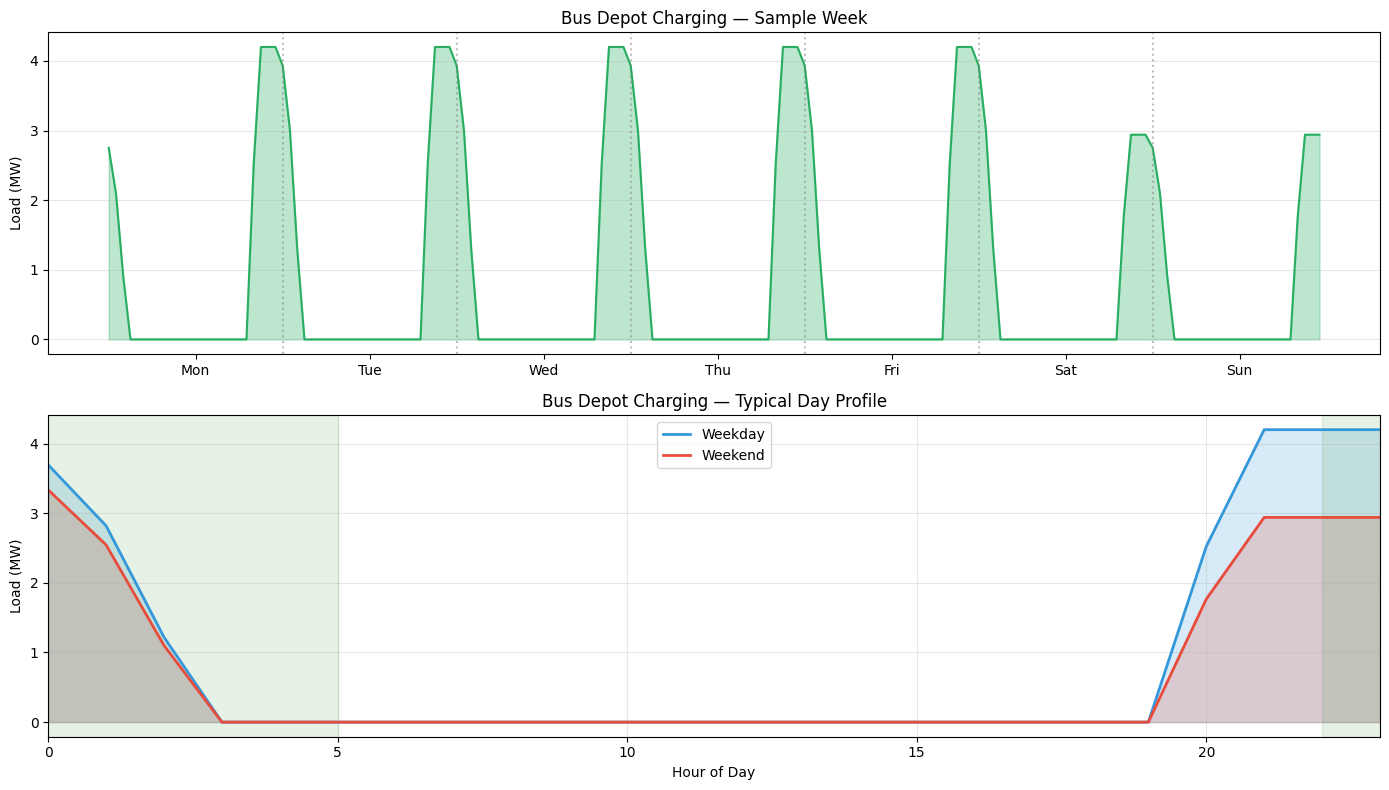

In [17]:
# ============================================================================
# GENERATE ANNUAL BUS DEPOT LOAD PROFILE
# ============================================================================

def generate_annual_bus_load(
    daily_profile: pd.DataFrame,
    year_index: pd.DatetimeIndex,
    weekend_factor: float = 0.7,  # Reduced weekend service
) -> pd.DataFrame:
    """
    Expand daily depot charging profile to annual hourly series.
    
    Applies weekend reduction factor for reduced service.
    """
    # Energy after midnight belongs to the previous evening's bus service.
    # This preserves weekday/weekend modulation consistently across day changes.
    year_index = pd.DatetimeIndex(year_index)
    source_days = year_index.normalize() - pd.to_timedelta((year_index.hour < BALLARAT_BUS_NETWORK.service_start_hour).astype(int), unit="D")
    day_factors = np.where(source_days.dayofweek >= 5, weekend_factor, 1.0)
    profile_kw = daily_profile.set_index("hour")["load_kw"]
    load_kw = profile_kw.reindex(year_index.hour).to_numpy() * day_factors

    return pd.DataFrame({
        'load_kw': load_kw,
        'load_mw': load_kw / 1000,
    }, index=year_index)

# Generate annual profile using "comfortable" charger scenario
bus_annual_load = generate_annual_bus_load(
    daily_profile=bus_load_profiles['comfortable'],
    year_index=HOURS,
    weekend_factor=0.7,
)

print("=" * 80)
print("BUS DEPOT — ANNUAL LOAD PROFILE")
print("=" * 80)
print(f"Peak load: {bus_annual_load['load_mw'].max():.2f} MW")
print(f"Mean load: {bus_annual_load['load_mw'].mean():.2f} MW")
print(f"Annual energy: {bus_annual_load['load_mw'].sum():.0f} MWh ({bus_annual_load['load_mw'].sum()/1000:.2f} GWh)")

# Visualize annual pattern
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Sample week
ax = axes[0]
sample_start = SAMPLE_WEEK_START
sample_end = SAMPLE_WEEK_END
sample = bus_annual_load.loc[(bus_annual_load.index >= sample_start) & (bus_annual_load.index < sample_end)]

ax.plot(range(len(sample)), sample['load_mw'].values, color='#27ae60', linewidth=1.5)
ax.fill_between(range(len(sample)), sample['load_mw'].values, alpha=0.3, color='#27ae60')

for d in range(1, 7):
    ax.axvline(x=d*24, color='grey', linestyle=':', alpha=0.5)
ax.set_xticks([12 + i*24 for i in range(7)])
ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax.set_ylabel('Load (MW)')
ax.set_title('Bus Depot Charging — Sample Week')
ax.grid(True, alpha=0.3, axis='y')

# Typical day comparison
ax = axes[1]
bus_annual_load['hour'] = bus_annual_load.index.hour
bus_annual_load['is_weekend'] = bus_annual_load.index.dayofweek >= 5

weekday_avg = bus_annual_load[~bus_annual_load['is_weekend']].groupby('hour')['load_mw'].mean()
weekend_avg = bus_annual_load[bus_annual_load['is_weekend']].groupby('hour')['load_mw'].mean()

ax.plot(weekday_avg.index, weekday_avg.values, label='Weekday', color='#3498db', linewidth=2)
ax.plot(weekend_avg.index, weekend_avg.values, label='Weekend', color='#e74c3c', linewidth=2)
ax.fill_between(weekday_avg.index, weekday_avg.values, alpha=0.2, color='#3498db')
ax.fill_between(weekend_avg.index, weekend_avg.values, alpha=0.2, color='#e74c3c')

ax.set_xlabel('Hour of Day')
ax.set_ylabel('Load (MW)')
ax.set_title('Bus Depot Charging — Typical Day Profile')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 23)

# Mark overnight window
ax.axvspan(22, 24, alpha=0.1, color='green')
ax.axvspan(0, 5, alpha=0.1, color='green')

plt.tight_layout()
plt.show()

# Cleanup
bus_annual_load.drop(columns=['hour', 'is_weekend'], inplace=True)

COMBINED EV CHARGING SITE — TRUCKS + BUSES

HEAVY HAUL TRUCKS (daytime charging):
  Peak: 7.56 MW
  Annual energy: 9.73 GWh

BUS DEPOT (overnight charging):
  Peak: 4.20 MW
  Annual energy: 7.79 GWh

COMBINED SITE:
  Peak: 7.56 MW
  Mean: 2.00 MW
  Annual energy: 17.52 GWh


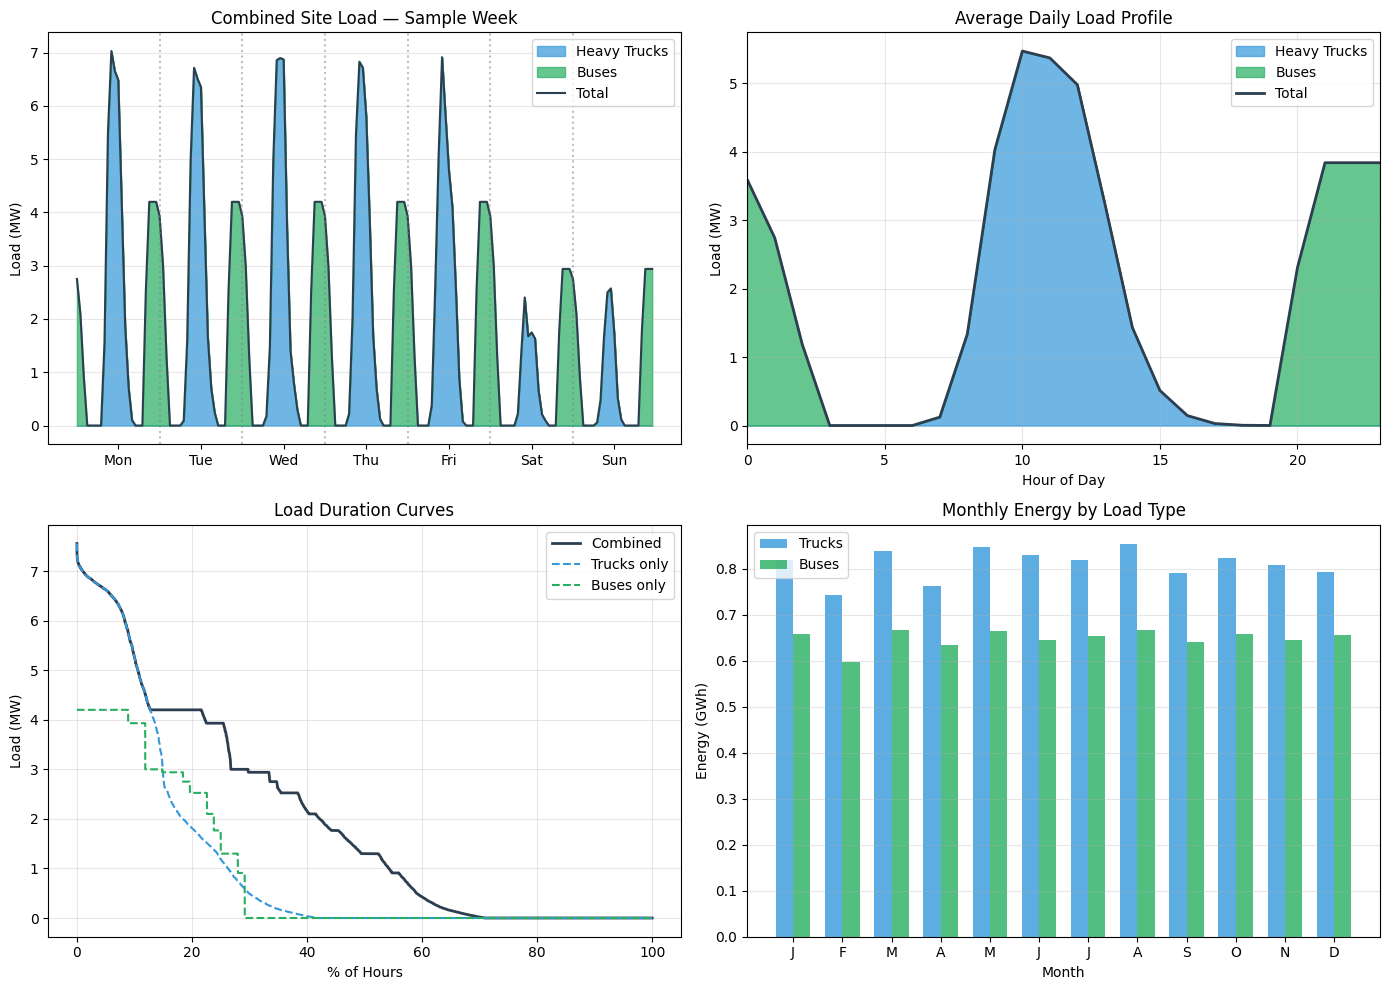


NOTE: Complementary load profiles!

The truck and bus charging loads are naturally complementary:
- Trucks charge during daytime (08:00-18:00) after Melbourne runs
- Buses charge overnight (22:00-05:00) after service ends

The combined coincidence of load needs to be checked using the simulated hourly time series.



In [18]:
# ============================================================================
# COMBINED SITE LOAD — TRUCKS + BUSES
# ============================================================================

# Combine the current truck EPM forecast with the independent bus depot model.
combined_load = pd.DataFrame({
    'trucks_mw': heavy_haul_load['load_mw'],  # FCFS truck charging events exported to EPM
    'buses_mw': bus_annual_load['load_mw'],
}, index=HOURS)

combined_load['total_mw'] = combined_load['trucks_mw'] + combined_load['buses_mw']

print("=" * 80)
print("COMBINED EV CHARGING SITE — TRUCKS + BUSES")
print("=" * 80)
print(f"\nHEAVY HAUL TRUCKS (daytime charging):")
print(f"  Peak: {combined_load['trucks_mw'].max():.2f} MW")
print(f"  Annual energy: {combined_load['trucks_mw'].sum()/1000:.2f} GWh")

print(f"\nBUS DEPOT (overnight charging):")
print(f"  Peak: {combined_load['buses_mw'].max():.2f} MW")
print(f"  Annual energy: {combined_load['buses_mw'].sum()/1000:.2f} GWh")

print(f"\nCOMBINED SITE:")
print(f"  Peak: {combined_load['total_mw'].max():.2f} MW")
print(f"  Mean: {combined_load['total_mw'].mean():.2f} MW")
print(f"  Annual energy: {combined_load['total_mw'].sum()/1000:.2f} GWh")

# Visualize combined load
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Sample week - stacked
ax = axes[0, 0]
sample_start = SAMPLE_WEEK_START
sample_end = SAMPLE_WEEK_END
sample = combined_load.loc[(combined_load.index >= sample_start) & (combined_load.index < sample_end)]

ax.fill_between(range(len(sample)), 0, sample['trucks_mw'].values, 
                alpha=0.7, color='#3498db', label='Heavy Trucks')
ax.fill_between(range(len(sample)), sample['trucks_mw'].values, 
                sample['trucks_mw'].values + sample['buses_mw'].values,
                alpha=0.7, color='#27ae60', label='Buses')
ax.plot(range(len(sample)), sample['total_mw'].values, 
        color='#2c3e50', linewidth=1.5, label='Total')

for d in range(1, 7):
    ax.axvline(x=d*24, color='grey', linestyle=':', alpha=0.5)
ax.set_xticks([12 + i*24 for i in range(7)])
ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax.set_ylabel('Load (MW)')
ax.set_title('Combined Site Load — Sample Week')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

# Typical 24-hour profile
ax = axes[0, 1]
combined_load['hour'] = combined_load.index.hour
hourly_avg = combined_load.groupby('hour').mean()

ax.fill_between(hourly_avg.index, 0, hourly_avg['trucks_mw'], 
                alpha=0.7, color='#3498db', label='Heavy Trucks')
ax.fill_between(hourly_avg.index, hourly_avg['trucks_mw'], 
                hourly_avg['trucks_mw'] + hourly_avg['buses_mw'],
                alpha=0.7, color='#27ae60', label='Buses')
ax.plot(hourly_avg.index, hourly_avg['total_mw'], 
        color='#2c3e50', linewidth=2, label='Total')

ax.set_xlabel('Hour of Day')
ax.set_ylabel('Load (MW)')
ax.set_title('Average Daily Load Profile')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 23)

# Load duration curve
ax = axes[1, 0]
sorted_total = np.sort(combined_load['total_mw'].values)[::-1]
sorted_trucks = np.sort(combined_load['trucks_mw'].values)[::-1]
sorted_buses = np.sort(combined_load['buses_mw'].values)[::-1]
x_pct = np.linspace(0, 100, len(sorted_total))

ax.plot(x_pct, sorted_total, color='#2c3e50', linewidth=2, label='Combined')
ax.plot(x_pct, sorted_trucks, color='#3498db', linewidth=1.5, linestyle='--', label='Trucks only')
ax.plot(x_pct, sorted_buses, color='#27ae60', linewidth=1.5, linestyle='--', label='Buses only')

ax.set_xlabel('% of Hours')
ax.set_ylabel('Load (MW)')
ax.set_title('Load Duration Curves')
ax.legend()
ax.grid(True, alpha=0.3)

# Monthly energy breakdown
ax = axes[1, 1]
combined_load['month'] = combined_load.index.month
monthly = combined_load.groupby('month')[['trucks_mw', 'buses_mw']].sum() / 1000  # GWh

x = np.arange(12)
width = 0.35
ax.bar(x - width/2, monthly['trucks_mw'], width, label='Trucks', color='#3498db', alpha=0.8)
ax.bar(x + width/2, monthly['buses_mw'], width, label='Buses', color='#27ae60', alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
ax.set_xlabel('Month')
ax.set_ylabel('Energy (GWh)')
ax.set_title('Monthly Energy by Load Type')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Cleanup and export combined hourly time series.
combined_load.drop(columns=['hour', 'month'], inplace=True)
combined_load.to_csv(OUTPUT_DIR / f"ballarat_hub_{YEAR}_combined_trucks_buses_hourly.csv", index_label="datetime")

print("\n" + "=" * 80)
print("NOTE: Complementary load profiles!")
print("=" * 80)
print("""
The truck and bus charging loads are naturally complementary:
- Trucks charge during daytime (08:00-18:00) after Melbourne runs
- Buses charge overnight (22:00-05:00) after service ends

The combined coincidence of load needs to be checked using the simulated hourly time series.
""")

## 12. Diesel Displacement — Combined Site Savings

Estimate the annual diesel fuel displaced by electrifying both the heavy truck fleet and the Ballarat bus fleet.

### Assumptions
- **Diesel truck**: ~40 L/100 km (44t GCW, refrigerated, highway)
- **Diesel bus**: ~42 L/100 km (urban single-decker, stop-start driving)
- **Diesel CO₂ factor**: 2.68 kg CO₂-e per litre (Scope 1, NGA 2024)
- **Diesel cost**: $1.75/L (wholesale ex-GST, indicative)

DIESEL DISPLACEMENT — ANNUAL SAVINGS

HEAVY TRUCKS (100 vehicles, 228.6 km mean per visit)
------------------------------------------------------------
  Annual vehicle-km:          6,664,827 km
  Diesel displaced:           2,665,931 litres
  CO₂ avoided:                    7,145 tonnes
  Fuel cost avoided:     $    4,665,379

BUS FLEET (76 vehicles, 257 km/day/bus)
------------------------------------------------------------
  Annual vehicle-km:          6,513,922 km
  Diesel displaced:           2,735,847 litres
  CO₂ avoided:                    7,332 tonnes
  Fuel cost avoided:     $    4,787,733

COMBINED SITE
  Total diesel displaced:     5,401,778 litres  (5.40 ML)
  Total CO₂ avoided:             14,477 tonnes
  Total fuel cost avoided: $  9,453,111  ($9.5M)

  Electricity consumed:           17.52 GWh
  Diesel-equivalent ratio: 308.4 L/MWh


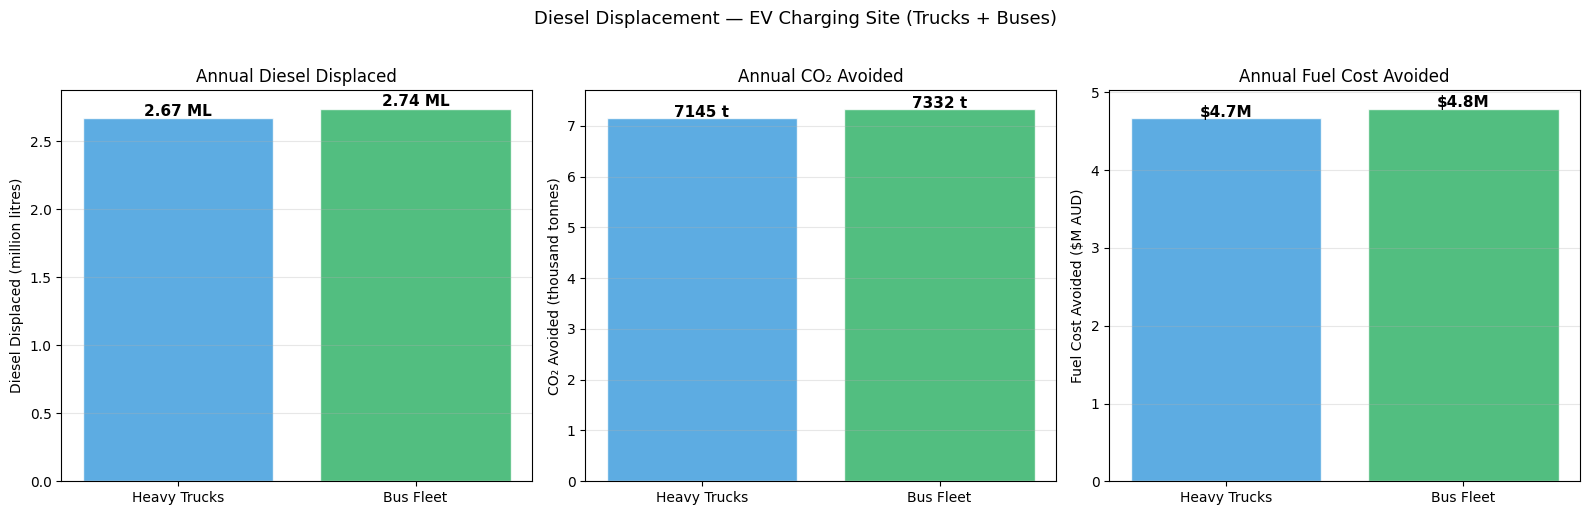

In [19]:
# ============================================================================
# DIESEL DISPLACEMENT CALCULATIONS
# ============================================================================

# Diesel consumption rates
DIESEL_TRUCK_L_PER_100KM = 40.0   # Heavy rigid/artic, refrigerated, highway
DIESEL_BUS_L_PER_100KM = 42.0     # Urban single-decker, stop-start
DIESEL_CO2_KG_PER_LITRE = 2.68    # NGA 2024 Scope 1
DIESEL_COST_PER_LITRE = 1.75      # AUD, wholesale ex-GST indicative

# ---- HEAVY TRUCKS — use the ACTUAL forecast trip distances/visits ----
truck_annual_km = float(truck_forecast["Trip Distance (km)"].sum())
truck_annual_diesel_L = truck_annual_km * DIESEL_TRUCK_L_PER_100KM / 100

# ---- BUSES — same weekday/weekend operating assumptions as annual bus model ----
year_days = pd.date_range(f"{YEAR}-01-01", f"{YEAR + 1}-01-01", freq="D", tz=TIMEZONE, inclusive="left")
bus_weekday_days = int((year_days.dayofweek < 5).sum())
bus_weekend_days = int((year_days.dayofweek >= 5).sum())
bus_annual_km = BALLARAT_BUS_NETWORK.fleet_size * BALLARAT_BUS_NETWORK.daily_km_per_bus * (bus_weekday_days + 0.7 * bus_weekend_days)
bus_annual_diesel_L = bus_annual_km * DIESEL_BUS_L_PER_100KM / 100

# ---- COMBINED ----
total_annual_diesel_L = truck_annual_diesel_L + bus_annual_diesel_L
total_annual_co2_t = total_annual_diesel_L * DIESEL_CO2_KG_PER_LITRE / 1000
total_annual_fuel_cost = total_annual_diesel_L * DIESEL_COST_PER_LITRE

# ---- PRINT SUMMARY ----
print("=" * 80)
print("DIESEL DISPLACEMENT — ANNUAL SAVINGS")
print("=" * 80)

sections = [
    ("HEAVY TRUCKS", truck_annual_km, truck_annual_diesel_L,
     hub.FLEET_SIZE,
     f"{truck_forecast['Trip Distance (km)'].mean():.1f} km mean per visit"),
    ("BUS FLEET", bus_annual_km, bus_annual_diesel_L,
     BALLARAT_BUS_NETWORK.fleet_size,
     f"{BALLARAT_BUS_NETWORK.daily_km_per_bus:.0f} km/day/bus"),
]

for label, km, litres, n_vehicles, route_desc in sections:
    co2 = litres * DIESEL_CO2_KG_PER_LITRE / 1000
    cost = litres * DIESEL_COST_PER_LITRE
    print(f"\n{label} ({n_vehicles} vehicles, {route_desc})")
    print("-" * 60)
    print(f"  Annual vehicle-km:     {km:>14,.0f} km")
    print(f"  Diesel displaced:      {litres:>14,.0f} litres")
    print(f"  CO₂ avoided:           {co2:>14,.0f} tonnes")
    print(f"  Fuel cost avoided:     ${cost:>13,.0f}")

print(f"\n{'COMBINED SITE':}")
print("=" * 60)
print(f"  Total diesel displaced:  {total_annual_diesel_L:>12,.0f} litres  ({total_annual_diesel_L/1e6:.2f} ML)")
print(f"  Total CO₂ avoided:       {total_annual_co2_t:>12,.0f} tonnes")
print(f"  Total fuel cost avoided: ${total_annual_fuel_cost:>11,.0f}  (${total_annual_fuel_cost/1e6:.1f}M)")

# Equivalent electricity consumed
truck_annual_gwh = combined_load['trucks_mw'].sum() / 1000
bus_annual_gwh = combined_load['buses_mw'].sum() / 1000
total_gwh = truck_annual_gwh + bus_annual_gwh

print(f"\n  Electricity consumed:    {total_gwh:>12.2f} GWh")
print(f"  Diesel-equivalent ratio: {total_annual_diesel_L / (total_gwh * 1e6) * 1000:.1f} L/MWh")

# ---- VISUALISATION ----
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Bar chart: diesel displaced
ax = axes[0]
categories = ['Heavy Trucks', 'Bus Fleet']
diesel_vals = [truck_annual_diesel_L / 1e6, bus_annual_diesel_L / 1e6]
colors = ['#3498db', '#27ae60']
bars = ax.bar(categories, diesel_vals, color=colors, alpha=0.8, edgecolor='white')
for bar, val in zip(bars, diesel_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{val:.2f} ML', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('Diesel Displaced (million litres)')
ax.set_title('Annual Diesel Displaced')
ax.grid(True, alpha=0.3, axis='y')

# Bar chart: CO2 avoided
ax = axes[1]
co2_vals = [truck_annual_diesel_L * DIESEL_CO2_KG_PER_LITRE / 1e6,
            bus_annual_diesel_L * DIESEL_CO2_KG_PER_LITRE / 1e6]
bars = ax.bar(categories, co2_vals, color=colors, alpha=0.8, edgecolor='white')
for bar, val in zip(bars, co2_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{val*1000:.0f} t', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('CO₂ Avoided (thousand tonnes)')
ax.set_title('Annual CO₂ Avoided')
ax.grid(True, alpha=0.3, axis='y')

# Bar chart: fuel cost avoided
ax = axes[2]
cost_vals = [truck_annual_diesel_L * DIESEL_COST_PER_LITRE / 1e6,
             bus_annual_diesel_L * DIESEL_COST_PER_LITRE / 1e6]
bars = ax.bar(categories, cost_vals, color=colors, alpha=0.8, edgecolor='white')
for bar, val in zip(bars, cost_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'${val:.1f}M', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('Fuel Cost Avoided ($M AUD)')
ax.set_title('Annual Fuel Cost Avoided')
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Diesel Displacement — EV Charging Site (Trucks + Buses)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
# Export results for later EPM/TEA reporting.
pd.DataFrame([{"year": YEAR, "truck_annual_km": truck_annual_km, "bus_annual_km": bus_annual_km, "truck_diesel_litres": truck_annual_diesel_L, "bus_diesel_litres": bus_annual_diesel_L, "total_diesel_litres": total_annual_diesel_L, "direct_co2_avoided_t": total_annual_co2_t, "diesel_fuel_cost_avoided_aud": total_annual_fuel_cost, "grid_energy_gwh": total_gwh}]).to_csv(OUTPUT_DIR / f"ballarat_hub_{YEAR}_diesel_displacement.csv", index=False)

## Model scope and known limitations

- **Truck EPM schedule:** fleet IDs, trips, charging requests, planned availability windows and chargers are generated by one module. Grid-side requested energy includes charging losses.
- **FCFS deadline infeasibility:** requests can finish after a planned departure. The module flags these cases but does **not** enforce a departure-limited delivered-energy constraint or update next-day SOC based on unmet requests. Thus exported grid energy is *requested and eventually charged*, not guaranteed feasible by each deadline.
- **Infrastructure comparisons:** 28/42/56 points change the number of 250 kW CCS chargers only. They do not model a mixed CCS/MCS fleet, variable charger power or EPM optimisation.
- **Bus profile:** a separate illustrative 76-bus depot model. Midnight charging energy is preserved in the repeating profile, but buses do not have individual EPM visits or SOC continuity.
- **Planning use:** trip distributions, refrigeration and arrival/departure times are synthetic. Calibrate using operator route and charging data prior to operational optimisation.